In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
font = {'size' : 15}
matplotlib.rc('font', **font)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})
from numpy.lib.stride_tricks import sliding_window_view
from skimage import measure
from scipy.spatial import ConvexHull
import os

In [2]:
os.makedirs("plots", exist_ok=True)
fields = [0.13, 0.14, 0.15, 0.16]
fields_colors = matplotlib.colormaps.get('tab10')(range(4))

# Width of arcs of length $\\ell$ about a line or a cubic, $w$ vs $X$
Same analysis as the bubble simulations (`bubble_sim/notes/interface_roughness/make_bubble_arc_figure.py`, fig11-14), functions copied from there.
The contour (NB3 definition: largest contour of inner domain + pixels switched up to $t$) is resampled at uniform arc length ($ds \\le 1$) and cut into arcs of length $\\ell$ (starting every $\\ell/4$). Two references:
- **line**: straight line along the chord through the mean point of the arc; $X$ = chord length. Removes mean and tilt ($\\zeta<2$).
- **cubic**: parametric cubic $x(s)$, $y(s)$ (a spline with no interior knot); deviation along its normal, $X$ = its length. Also removes the curvature ($\\zeta<4$).

$w^2(\\ell)$ = mean square deviation. Each field on its own, 20 frames in the last 40\\% of the growth (`late`) and 20 frames in $[0.2, 0.4]\\,T$ (`early`); error bars = 95\\% bootstrap over frames (frames are correlated in time, so they are a lower bound).

### FUNCTIONS

In [3]:
def segment_noevents(data, no_event_val=-1):
    no_event_regions = [ r.astype('int') for r in measure.find_contours(data,no_event_val)]
    no_event_regions_sizes = np.array([r.shape[0] for r in no_event_regions])
    sorted_regions_idx = np.argsort(no_event_regions_sizes)
    inner_region = no_event_regions[sorted_regions_idx[-2]]
    outer_region = no_event_regions[sorted_regions_idx[-1]]
    center = inner_region.mean(axis=0)
    return inner_region,  outer_region, center

In [4]:
def get_inner_mask(data, inner_region):
    # same as NB3: mask of the inner (initial) domain from the convex hull of inner_region
    nrows, ncols = data.shape
    ii, jj = np.meshgrid(np.arange(0,nrows), np.arange(0,ncols), indexing='ij')
    pts = np.vstack([ii.flatten(), jj.flatten()])
    inner_hull = ConvexHull(inner_region)
    inner_mask = np.ones((nrows, ncols), dtype=bool)
    for eq in inner_hull.equations:
        eq_mask = np.dot(eq[:-1], pts) + eq[-1] <= 1e-12
        inner_mask[ii.flatten(),jj.flatten()] *= eq_mask
    return inner_mask

In [5]:
def get_contour(data, inner_mask, t):
    # same contour as NB3 (sub-pixel, not cast to int), closed, without repeated points
    temp = np.zeros_like(data)
    temp[inner_mask] = 1
    temp[(data > -1)*(data<=t)] = 1
    regions = measure.find_contours(temp)
    r_sizes = [len(r) for r in regions]
    largest_r = regions[np.argmax(r_sizes)]
    largest_r = largest_r[np.r_[True, np.linalg.norm(np.diff(largest_r, axis=0), axis=1) > 0]]
    return largest_r

In [6]:
# from bubble_sim/notes/interface_roughness/make_bubble_arc_figure.py
DEGREE = 3
ELLS = np.unique(np.rint(np.geomspace(8, 4096, 28)))
RNG = np.random.default_rng(20261124)


def resample(line):
    """Uniform arc-length points of one period of the contour, ds = P/N <= 1."""
    length = np.r_[0., np.cumsum(np.linalg.norm(np.diff(line, axis=0), axis=1))]
    P = length[-1]
    N = int(np.ceil(P))
    s = np.arange(N)*P/N
    return np.stack((np.interp(s, length, line[:, 0]), np.interp(s, length, line[:, 1])), 1), P/N


def arcs(points, ds, shift, ell, method, degree=DEGREE, every=1):
    """Arcs of length ell starting every n/4 points (every: keep one arc in that many).
    Returns the arcs (k, 2, n), the reference curves, the normal deviations (k, n), the lengths X
    and the direction of the chord normal folded to [0, 90] degrees from the x axis."""
    N, n = len(points), int(round(ell/ds))
    extended = np.vstack((points, points[:n] + shift))
    W = sliding_window_view(extended, n, axis=0)[:N:max(1, n//4)*every]
    chord = W[:, :, -1] - W[:, :, 0]
    angle = np.mod(np.degrees(np.arctan2(chord[:, 1], chord[:, 0])) + 90, 180)
    phi = np.minimum(angle, 180 - angle)
    if method == "line":
        X = np.linalg.norm(chord, axis=1)
        tangent = chord/X[:, None]
        normal = np.stack((-tangent[:, 1], tangent[:, 0]), 1)
        centre = W.mean(axis=2)
        relative = W - centre[:, :, None]
        deviation = np.einsum("kin,ki->kn", relative, normal)
        along = np.einsum("kin,ki->kn", relative, tangent)
        ends = np.stack((along.min(axis=1), along.max(axis=1)), 1)
        line = centre[:, :, None] + tangent[:, :, None]*ends[:, None, :]
        return W, line, deviation, X, phi
    t = np.linspace(-1, 1, n)
    V = np.vander(t, degree+1)
    coefficients = np.linalg.lstsq(V, np.moveaxis(W, -1, 0).reshape(n, -1), rcond=None)[0]
    fit = np.moveaxis((V @ coefficients).reshape(n, *W.shape[:2]), 0, -1)
    derivative = np.vander(t, degree)*np.arange(degree, 0, -1)
    tangent = np.moveaxis((derivative @ coefficients[:-1]).reshape(n, *W.shape[:2]), 0, -1)
    speed = np.linalg.norm(tangent, axis=1)
    normal = np.stack((-tangent[:, 1], tangent[:, 0]), 1)/speed[:, None]
    deviation = np.sum((W - fit)*normal, axis=1)
    X = np.trapezoid(speed, t, axis=1)
    return W, fit, deviation, X, phi


def widths(points, ds, shift, P, method, sector=None):
    """Per contour: mean square deviation and mean fitted length at every ell <= P/4,
    over the arcs whose folded normal direction lies in sector (all arcs if None)."""
    w2, X = np.full(len(ELLS), np.nan), np.full(len(ELLS), np.nan)
    for j, ell in enumerate(ELLS):
        if ell <= P/4:
            _, _, d, x, phi = arcs(points, ds, shift, ell, method)
            take = np.ones(len(x), bool) if sector is None else (phi >= sector[0]) & (phi < sector[1])
            if take.any():
                w2[j], X[j] = np.mean(d[take]**2), np.mean(x[take])
    return w2, X


def ensemble(w2, X, draws, complete=1.):
    """Mean width, mean fitted length, local exponent d ln w / d ln X and its 95% bootstrap interval,
    at the ell where at least the fraction complete of the contours contribute."""
    keep = np.mean(np.isfinite(w2), axis=0) >= complete
    mean = lambda a: np.nanmean(a[..., keep], axis=-2)
    slope = lambda a, b: np.gradient(.5*np.log(a), np.log(b), axis=-1)
    boot = np.array([slope(mean(w2[i]), mean(X[i])) for i in draws])
    return dict(ell=ELLS[keep], w=np.sqrt(mean(w2)), X=mean(X), zeta=slope(mean(w2), mean(X)),
                zeta_ell=np.gradient(.5*np.log(mean(w2)), np.log(ELLS[keep])),
                ci95=np.quantile(boot, [.025, .975], axis=0), n=len(w2))

### EXECUTION

In [7]:
methods = ["line", "cubic"]
windows = {"early": (0.2, 0.4), "late": (0.6, 1.0)}
n_frames = 20
arc_dict = {}
example_dict = {}
for field in fields:
    print(field)
    data = np.loadtxt("data/file_field%1.2f.csv" % field, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(data)
    inner_mask = get_inner_mask(data, inner_region)
    T = data.max()
    arc_dict[field] = {}
    for window, (f0, f1) in windows.items():
        t_list = np.linspace(f0*T, f1*T, n_frames).astype('int')
        rows = {method: [] for method in methods}
        for t in t_list:
            h = get_contour(data, inner_mask, t)
            points, ds = resample(h[:-1])
            for method in methods:
                rows[method].append(widths(points, ds, np.zeros(2), len(points)*ds, method))
        draws = RNG.integers(n_frames, size=(2000, n_frames))
        for method in methods:
            w2, X = map(np.array, zip(*rows[method]))
            arc_dict[field][(window, method)] = ensemble(w2, X, draws)
    example_dict[field] = (get_contour(data, inner_mask, T), points, ds)

0.13


0.14


0.15


0.16


In [8]:
# local exponent of the cubic in the late window, averaged over X in [10, 300] px
for field in fields:
    for window in windows:
        r = arc_dict[field][(window, "cubic")]
        m = (r["X"] > 10)*(r["X"] < 300)
        print("%1.2f  %-5s  cubic: zeta(X) = %s   mean over 10 < X < 300: %.2f   largest X %i" % (field, window, ' '.join('%.2f' % z for z in r["zeta"][m]), r["zeta"][m].mean(), r["X"][-1]))

0.13  early  cubic: zeta(X) = 0.82 0.83 0.87 0.88 0.82 0.75 0.68 0.64 0.62 0.59 0.54 0.52 0.53 0.52 0.48   mean over 10 < X < 300: 0.67   largest X 284
0.13  late   cubic: zeta(X) = 0.84 0.83 0.82 0.80 0.81 0.80 0.78 0.75 0.71 0.68 0.68 0.69 0.70 0.69 0.62   mean over 10 < X < 300: 0.75   largest X 440
0.14  early  cubic: zeta(X) = 0.69 0.69 0.70 0.72 0.71 0.69 0.70 0.72 0.73 0.66 0.62 0.62 0.61 0.64 0.65   mean over 10 < X < 300: 0.68   largest X 295
0.14  late   cubic: zeta(X) = 0.69 0.70 0.72 0.74 0.75 0.73 0.71 0.70 0.65 0.61 0.62 0.61 0.62 0.66 0.64   mean over 10 < X < 300: 0.68   largest X 466
0.15  early  cubic: zeta(X) = 0.60 0.60 0.64 0.67 0.69 0.70 0.71 0.71 0.70 0.68 0.68 0.69 0.67 0.63 0.63   mean over 10 < X < 300: 0.66   largest X 297
0.15  late   cubic: zeta(X) = 0.64 0.64 0.66 0.68 0.69 0.70 0.70 0.70 0.72 0.75 0.75 0.71 0.62 0.58 0.60   mean over 10 < X < 300: 0.68   largest X 469
0.16  early  cubic: zeta(X) = 0.56 0.56 0.58 0.61 0.62 0.64 0.68 0.73 0.77 0.80 0.80 0.7

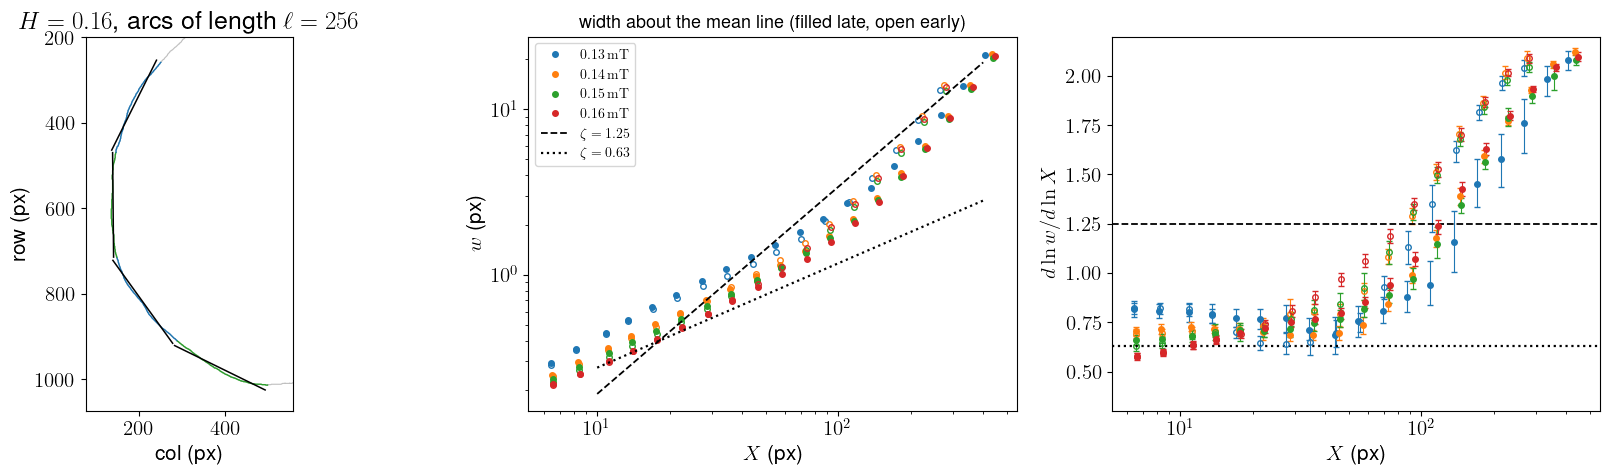

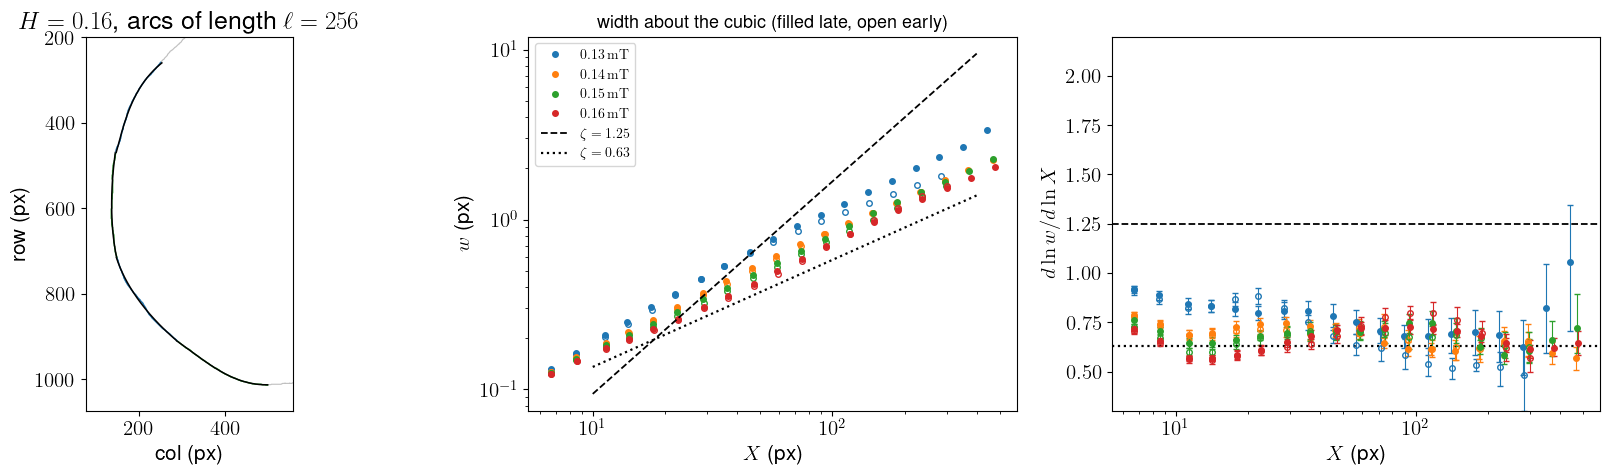

In [9]:
for method in methods:
    fig, ax = plt.subplots(figsize=(17,5), ncols=3)
    # (a) example arcs, field 0.16, last frame
    line, points, ds = example_dict[0.16]
    ax[0].plot(line[:, 1], line[:, 0], color='0.75', lw=0.8)
    W, fit, _, _, phi = arcs(points, ds, np.zeros(2), 256, method, every=4)
    for j in range(4):
        ax[0].plot(W[j, 1], W[j, 0], color=['C2', 'C0'][j % 2], lw=1)
        ax[0].plot(fit[j, 1], fit[j, 0], color='black', lw=1.1)
    lo, hi = W[:4].min(axis=(0, 2)), W[:4].max(axis=(0, 2))
    pad = 0.08*max(hi-lo)
    ax[0].set_xlim(lo[1]-pad, hi[1]+pad)
    ax[0].set_ylim(hi[0]+pad, lo[0]-pad)
    ax[0].set_aspect('equal')
    ax[0].set_title("$H=0.16$, arcs of length $\\ell=256$")
    ax[0].set_xlabel("col (px)")
    ax[0].set_ylabel("row (px)")
    for color, field in zip(fields_colors, fields):
        for window, mfc in zip(windows, ['none', None]):
            r = arc_dict[field][(window, method)]
            kw = dict(mfc='none') if mfc == 'none' else dict()
            ax[1].loglog(r["X"], r["w"], ls='none', marker='o', ms=4, color=color, label="$%1.2f \\, \\rm{mT}$" % field if window == "late" else None, **kw)
            ax[2].errorbar(r["X"], r["zeta"], yerr=np.abs(r["ci95"]-r["zeta"]), ls='none', marker='o', ms=4, capsize=2, lw=0.8, color=color, **kw)
    xx = np.geomspace(10, 400, 100)
    r = arc_dict[0.16][("late", method)]
    anchor = np.exp(np.interp(np.log(50), np.log(r["X"]), np.log(r["w"])))
    ax[1].plot(xx, 1.6*anchor*(xx/50)**1.25, '--', color='black', lw=1.3, label="$\\zeta=1.25$")
    ax[1].plot(xx, 0.85*anchor*(xx/50)**0.63, ':', color='black', lw=1.6, label="$\\zeta=0.63$")
    ax[1].set_xlabel("$X$ (px)")
    ax[1].set_ylabel("$w$ (px)")
    ax[1].set_title("width about the %s (filled late, open early)" % ("mean line" if method == "line" else "cubic"), fontsize=13)
    ax[1].legend(fontsize=10)
    ax[2].axhline(1.25, ls='--', color='black', lw=1.3)
    ax[2].axhline(0.63, ls=':', color='black', lw=1.6)
    ax[2].set_xscale('log')
    ax[2].set_ylim(0.3, 2.2)
    ax[2].set_xlabel("$X$ (px)")
    ax[2].set_ylabel("$d\\ln w/d\\ln X$")
    plt.tight_layout()
    plt.savefig("plots/arc_width_%s.pdf" % method, bbox_inches='tight')
    plt.show()

### $w(X)$ in time windows, each field separately
Cubic reference. 5 windows of equal length in $t$, 10 frames each; $\\langle R \\rangle$ from the interfaces of NB3.

In [10]:
source_folder = "interface_data/"
time_windows = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
n_frames_w = 10
window_dict = {}
for field in fields:
    print(field)
    data = np.loadtxt("data/file_field%1.2f.csv" % field, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(data)
    inner_mask = get_inner_mask(data, inner_region)
    interface = np.load("%sinterface_field=%1.2f.npz" % (source_folder,field))['interface']
    T = data.max()
    window_dict[field] = []
    for f0, f1 in time_windows:
        t_list = np.linspace(f0*T, f1*T, n_frames_w+1)[1:].astype('int')   # skip t = 0 (initial domain only)
        rows = []
        for t in t_list:
            h = get_contour(data, inner_mask, t)
            points, ds = resample(h[:-1])
            rows.append(widths(points, ds, np.zeros(2), len(points)*ds, "cubic"))
        w2, X = map(np.array, zip(*rows))
        r = ensemble(w2, X, RNG.integers(n_frames_w, size=(2000, n_frames_w)))
        R_mean = interface[t_list, :-1].mean(axis=1)
        window_dict[field].append((t_list, R_mean, r))

0.13


0.14


0.15


0.16


In [11]:
# w at fixed X and mean local exponent, per field and window
X_ref = [20, 50, 150]
for field in fields:
    print("H = %1.2f" % field)
    for (f0, f1), (t_list, R_mean, r) in zip(time_windows, window_dict[field]):
        w_ref = [ np.exp(np.interp(np.log(x), np.log(r["X"]), np.log(r["w"]), left=np.nan, right=np.nan)) for x in X_ref]
        m = (r["X"] > 10)*(r["X"] < 300)
        print("   t in [%i, %i]  <R> = %3i-%3i px   w(X=%i, %i, %i) = %s px   zeta (10 < X < 300) = %.2f   largest X = %i" % (t_list[0], t_list[-1], R_mean[0], R_mean[-1], X_ref[0], X_ref[1], X_ref[2], ' '.join('%.2f' % w for w in w_ref), r["zeta"][m].mean(), r["X"][-1]))

H = 0.13
   t in [1157, 11573]  <R> = 119-198 px   w(X=20, 50, 150) = 0.35 0.72 1.37 px   zeta (10 < X < 300) = 0.71   largest X = 176
   t in [12730, 23146]  <R> = 206-265 px   w(X=20, 50, 150) = 0.33 0.68 1.33 px   zeta (10 < X < 300) = 0.67   largest X = 283
   t in [24303, 34719]  <R> = 270-318 px   w(X=20, 50, 150) = 0.33 0.69 1.45 px   zeta (10 < X < 300) = 0.70   largest X = 352
   t in [35876, 46292]  <R> = 320-358 px   w(X=20, 50, 150) = 0.32 0.61 1.22 px   zeta (10 < X < 300) = 0.69   largest X = 460
   t in [47450, 57866]  <R> = 363-401 px   w(X=20, 50, 150) = 0.35 0.76 1.78 px   zeta (10 < X < 300) = 0.78   largest X = 422
H = 0.14
   t in [1207, 12075]  <R> =  97-194 px   w(X=20, 50, 150) = 0.30 0.60 nan px   zeta (10 < X < 300) = 0.70   largest X = 144
   t in [13282, 24150]  <R> = 203-267 px   w(X=20, 50, 150) = 0.28 0.53 1.11 px   zeta (10 < X < 300) = 0.66   largest X = 295
   t in [25357, 36225]  <R> = 273-325 px   w(X=20, 50, 150) = 0.27 0.52 1.12 px   zeta (10 < X <

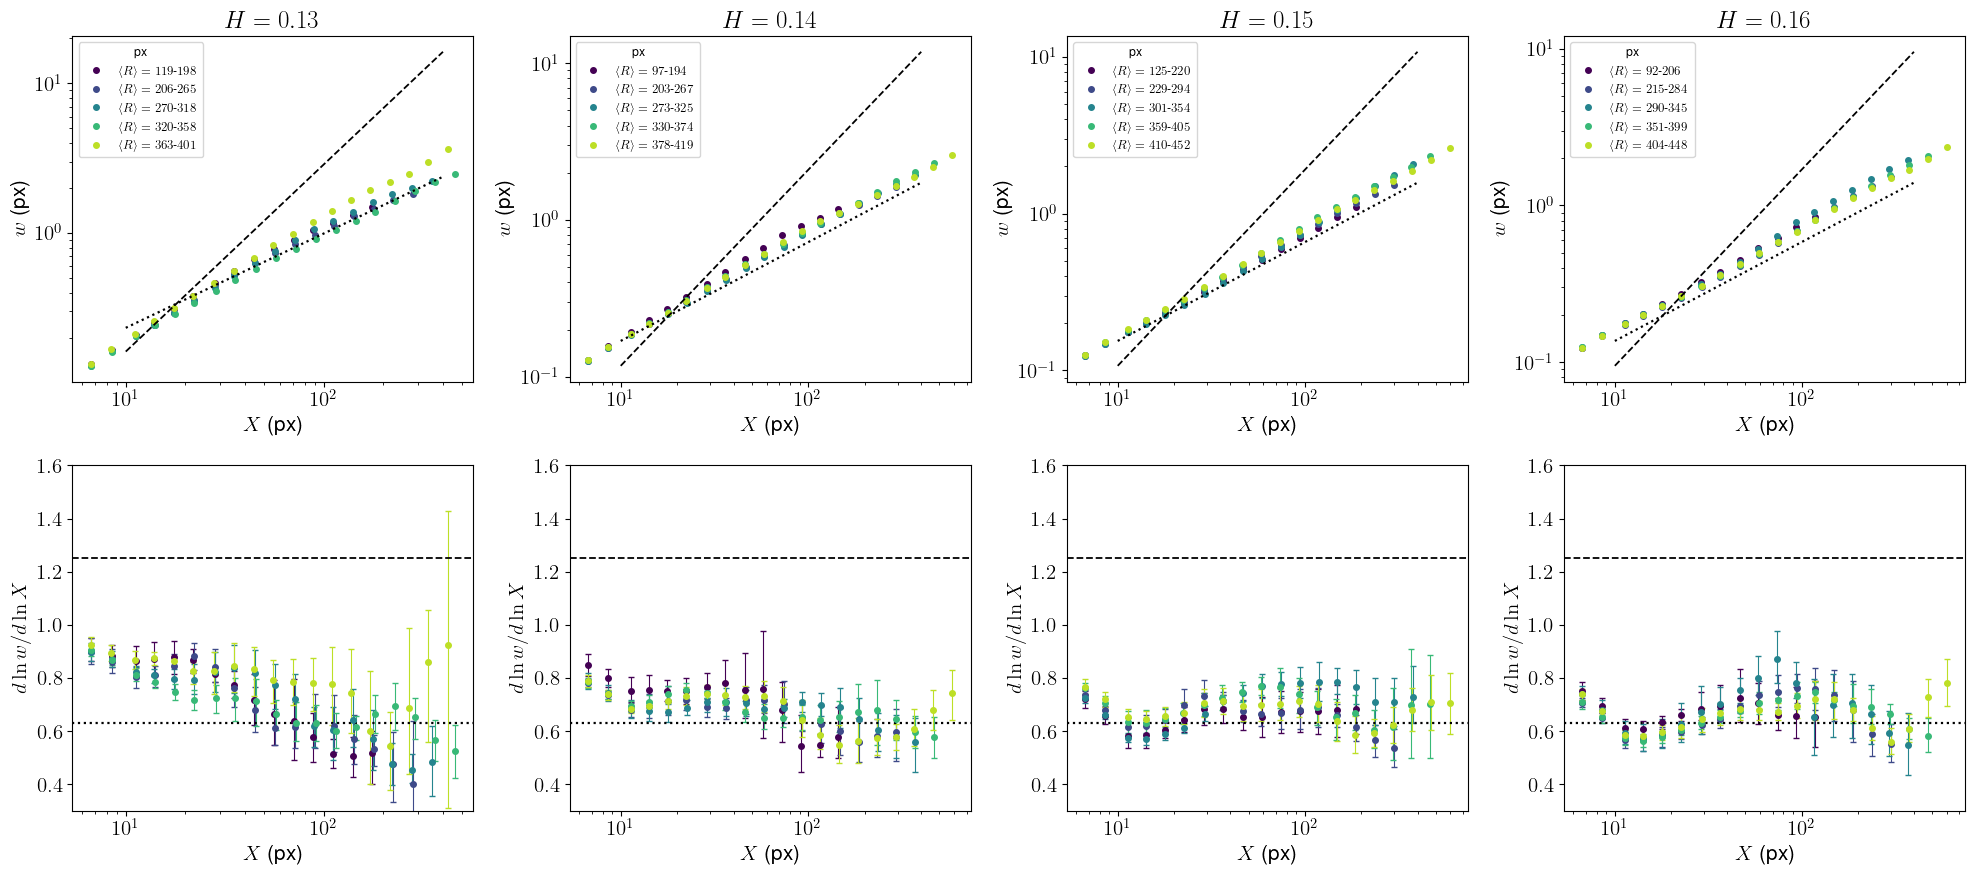

In [12]:
windows_colors = matplotlib.colormaps.get('viridis')(np.linspace(0, 0.9, len(time_windows)))
fig, ax = plt.subplots(figsize=(20,9), ncols=4, nrows=2)
for i, field in enumerate(fields):
    for color, (t_list, R_mean, r) in zip(windows_colors, window_dict[field]):
        lbl = "$\\langle R \\rangle = %i$-$%i$" % (R_mean[0], R_mean[-1])
        ax[0, i].loglog(r["X"], r["w"], ls='none', marker='o', ms=4, color=color, label=lbl)
        ax[1, i].errorbar(r["X"], r["zeta"], yerr=np.abs(r["ci95"]-r["zeta"]), ls='none', marker='o', ms=4, capsize=2, lw=0.8, color=color)
    xx = np.geomspace(10, 400, 100)
    r = window_dict[field][-1][2]
    anchor = np.exp(np.interp(np.log(50), np.log(r["X"]), np.log(r["w"])))
    ax[0, i].plot(xx, 1.6*anchor*(xx/50)**1.25, '--', color='black', lw=1.3)
    ax[0, i].plot(xx, 0.85*anchor*(xx/50)**0.63, ':', color='black', lw=1.6)
    ax[0, i].set_title("$H=%1.2f$" % field)
    ax[0, i].set_xlabel("$X$ (px)")
    ax[0, i].set_ylabel("$w$ (px)")
    ax[0, i].legend(fontsize=9, title="px", title_fontsize=9)
    ax[1, i].axhline(1.25, ls='--', color='black', lw=1.3)
    ax[1, i].axhline(0.63, ls=':', color='black', lw=1.6)
    ax[1, i].set_xscale('log')
    ax[1, i].set_ylim(0.3, 1.6)
    ax[1, i].set_xlabel("$X$ (px)")
    ax[1, i].set_ylabel("$d\\ln w/d\\ln X$")
plt.tight_layout()
plt.savefig("plots/arc_width_cubic_windows.pdf", bbox_inches='tight')
plt.show()